# Wan reverse-time experiment: ALL 81 frames, 600 optimizer updates
This notebook uses the existing 40 Wan teacher clips in `data/wan_pilot_v1` on whichever Drive you mount. It is self-contained with the accompanying source ZIP; it does not require the newer 17-frame checkpoints from your other Drive.

**Input:** original forward-action prompt. **Desired output:** direct reverse-time action. There is no reverse-caption rewrite or post-generation frame reversal.

Preset: **81 frames, 256×448, rank-16 LoRA, FP16, 600 updates, accumulation 2, CFG=1, 50 sampling steps**. Playback is 16 fps (5.06 s). Source videos are expected to contain exactly 81 frames. All 81 frames are used; spatial resolution is reduced. This is not training at the original 480×832 resolution.

**T4 fit and runtime are not established by the previous 17-frame smoke.** First encode ONE clip and test a real 81-frame backward/update/reload. Continue only if that succeeds. No automatic frame/resolution fallback is used. Extra frames preserve temporal detail but do not guarantee inverse-action success.

The loss/architecture are the V3 experiment: fresh flow matching + 0.1 normalized latent-motion loss + 0.1 endpoint-order hinge. Default velocity-KD weight is zero; supervision comes from reversed teacher-generated videos (teacher-sample distillation). This is not a velocity-KD experiment.

## 1. Mount the destination Drive and copy the supplied code
Extract `Wan_81Frames_600Steps_Code.zip` into `My Drive/reverse_video_project` on the **destination account**. Replace matching source files, keep all data/runs. Open this NEW notebook from that Drive and authorize the intended Drive account.

You do not need to copy the 17-frame V3 run from the other account. Before continuing, verify the manifest and source frames below. The notebook operates only on the Drive mounted at `/content/drive`.

In [1]:
import os,sys,json,subprocess,shutil,time,hashlib
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
SOURCE=Path('/content/drive/MyDrive/reverse_video_project')
LOCAL=Path('/content/wan81_code');LOCAL.mkdir(exist_ok=True)
WORK=Path('/content/wan_reverse_work');WORK.mkdir(exist_ok=True)
for name in ('wan_reverse','wan_refine','tests_refine','configs'):
    assert (SOURCE/name).exists(),f'Missing {name}: extract the NEW source ZIP into this project first.'
    shutil.copytree(SOURCE/name,LOCAL/name,dirs_exist_ok=True,ignore=shutil.ignore_patterns('__pycache__'))
shutil.copy2(SOURCE/'requirements-wan.txt',LOCAL/'requirements-wan.txt')
assert (SOURCE/'data/wan_pilot_v1/manifest_wan.jsonl').exists(),'Missing dataset manifest in this Drive.'
assert (LOCAL/'configs/wan_81_t4.json').exists(),'The NEW 81-frame source package has not been extracted.'
ENV=os.environ.copy();ENV.pop('PYTHONPATH',None);ENV.pop('PYTHONHOME',None)
ENV.update(USE_TF='0',USE_FLAX='0',TOKENIZERS_PARALLELISM='false',HF_HOME=str(WORK/'hf_cache'),PYTORCH_CUDA_ALLOC_CONF='expandable_segments:True')
PY=WORK/'env/bin/python'
def stream(args,env=None):
    print('Running:',' '.join(map(str,args)),flush=True)
    process=subprocess.Popen(list(map(str,args)),cwd=LOCAL,env=env or ENV,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    try:
        for line in process.stdout:print(line,end='',flush=True)
        status=process.wait()
        if status:raise subprocess.CalledProcessError(status,args)
    except BaseException:
        if process.poll() is None:
            process.terminate()
            try:process.wait(timeout=5)
            except subprocess.TimeoutExpired:process.kill();process.wait()
        raise
stream(['nvidia-smi'])
print('Project in mounted Drive:',SOURCE)
print('Local free disk GiB:',round(shutil.disk_usage(WORK).free/2**30,1))

Mounted at /content/drive
Running: nvidia-smi
Mon Oct 26 15:06:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-

## 2. Install Python 3.11 and pinned dependencies
This reuses the earlier isolated environment if it exists in the current VM; a new Colab VM needs installation again. It does not downgrade the Colab kernel's Python. CPU component tests include an 81-frame tiny Wan/VAE path; they do not prove full-model CUDA fit.

In [2]:
BOOT=WORK/'uv_bootstrap'
stream([sys.executable,'-m','pip','install','--target',BOOT,'uv==0.8.22'])
UV_ENV=ENV.copy();UV_ENV.update(PYTHONPATH=str(BOOT),UV_PYTHON_INSTALL_DIR=str(WORK/'python'),UV_PYTHON_PREFERENCE='only-managed',UV_CACHE_DIR=str(WORK/'uv_cache'))
if not PY.exists():
    stream([sys.executable,'-m','uv','python','install','3.11'],UV_ENV)
    stream([sys.executable,'-m','uv','venv','--python','3.11','--seed',WORK/'env'],UV_ENV)
stream([PY,'-m','pip','install','pip==25.0.1'])
stream([PY,'-m','pip','install','torch==2.5.1','--index-url','https://download.pytorch.org/whl/cu121'])
stream([PY,'-m','pip','install','--only-binary=:all:','-r',LOCAL/'requirements-wan.txt'])
stream([PY,'-m','pip','check'])
stream([PY,'-c',"import torch; assert torch.cuda.is_available(), 'Select GPU runtime'; print(torch.cuda.get_device_name(0), torch.__version__)"])
stream([PY,'-m','pytest','-q','tests_refine'])

Running: /usr/bin/python3 -m pip install --target /content/wan_reverse_work/uv_bootstrap uv==0.8.22
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 25.9 MB/s  0:00:00
Running: /usr/bin/python3 -m uv python install 3.11
Installed Python 3.11.17 in 1.12s
 + cpython-3.11.17-linux-x86_64-gnu (python3.11)
Running: /usr/bin/python3 -m uv venv --python 3.11 --seed /content/wan_reverse_work/env
Using CPython 3.11.17
Creating virtual environment with seed packages at: /content/wan_reverse_work/env
 + packaging==26.3
 + pip==26.2.2
 + setuptools==84.2.1
 + wheel==0.48.0
Activate with: source /content/wan_reverse_work/env/bin/activate
Running: /content/wan_reverse_work/env/bin/python -m pip install pip==25.0.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 43.1 MB/s  0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 26.2.2
    Uninstalling pip-26.2.2:
      Successfully uninstalled pip-26.2.2
Running: /content/wan_reverse_work/env/bin/python -m pip install 

## 3. Create or resume the NEW 81-frame configuration
Default run is `runs/wan_v3_81f_600`. Existing config is reused, never silently overwritten. No old checkpoint/optimizer state is copied: training begins at step 1 in this experiment. Later disconnects resume this experiment's own checkpoint.

If you knowingly change resolution/rank/losses, create another RUN_NAME first. Do not edit a saved run in place. Keep `frames=81` and inspect any changed preset with a new smoke test.

In [3]:
RUN_NAME='wan_v3_81f_600'
RUN=SOURCE/'runs'/RUN_NAME;RUN.mkdir(parents=True,exist_ok=True)
CFG=RUN/'config.json'
manifest=[json.loads(line) for line in (SOURCE/'data/wan_pilot_v1/manifest_wan.jsonl').read_text().splitlines() if line.strip()]
if CFG.exists():
    C=json.loads(CFG.read_text());print('Reusing saved config:',CFG)
else:
    C=json.loads((LOCAL/'configs/wan_81_t4.json').read_text())
    C.update(dataset_dir=str(SOURCE/'data/wan_pilot_v1'),run_dir=str(RUN),work_dir=str(WORK),train_ids=[r['id'] for r in manifest if r['split']=='train'])
    # Prepared tensors belong to THIS 81-frame run, never an old 17-frame run.
    C.pop('prepared_run_dir',None);C.pop('cache_run_dir',None)
    CFG.write_text(json.dumps(C,indent=2))
assert C['frames']==81 and C['max_steps']==600 and C.get('require_all_81_frames')
assert Path(C.get('prepared_run_dir',C['run_dir']))==RUN,'Do not use old 17-frame prepared latents.'
assert C['run_dir']==str(RUN) and C['dataset_dir']==str(SOURCE/'data/wan_pilot_v1')
assert len(C['train_ids'])==32 and len(manifest)==40
assert manifest[0]['split']=='train','The one-clip preparation must begin with a training record.'
print(json.dumps(C,indent=2))
def run(module,*args,config_path=None):
    stream([PY,'-u','-m',module,'--config',config_path or CFG,*map(str,args)])
# Retains checksums and the explicit user-declared acceptance assumption.
run('wan_reverse.audit')

Reusing saved config: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json
{
  "model_id": "Wan-AI/Wan2.1-T2V-1.3B-Diffusers",
  "revision": "0fad780a534b6463e45facd96134c9f345acfa5b",
  "dataset_dir": "/content/drive/MyDrive/reverse_video_project/data/wan_pilot_v1",
  "work_dir": "/content/wan_reverse_work",
  "run_dir": "/content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600",
  "accept_all_user_declared": true,
  "expected_candidates": 40,
  "height": 256,
  "width": 448,
  "frames": 81,
  "fps": 16,
  "precision": "fp16",
  "rank": 16,
  "lora_alpha": 16,
  "learning_rate": 0.0002,
  "weight_decay": 0.01,
  "max_steps": 600,
  "accumulate": 2,
  "gradient_clip": 1.0,
  "cache_draws_train": 8,
  "cache_draws_eval": 4,
  "conditioning_dropout": 0.1,
  "sigma_min": 0.02,
  "sigma_max": 0.98,
  "flow_weight": 1.0,
  "kd_weight": 0.0,
  "temporal_weight": 0.05,
  "checkpoint_every": 25,
  "validate_every": 50,
  "seed": 20261023,
  "inference_steps": 50

## 4. Prepare ONE clip, then measure a REAL 81-frame update
The VAE encodes forward pixels and reversed pixels separately. Saved 17-frame latents cannot be reused. Model downloads may be several GB. The smoke uses an already committed training clip even while preparation is partial; actual training refuses partial preparation.

If this cell fails with CUDA OOM, STOP before preparing the other 39 clips. Do not assume inference fit implies training fit. Keep the error and measured GPU details. The notebook does not silently switch to 17/33 frames. A lower spatial-resolution 81-frame run would need an explicit new run name/config and another smoke test.

In [ ]:
run('wan_reverse.prepare','--limit',1)
run('wan_refine.train','--smoke')
smoke=json.loads((RUN/'gpu_smoke_v3.json').read_text())
print(json.dumps(smoke,indent=2))
assert smoke.get('frames')==81,'Old source/smoke detected: extract the NEW package.'
assert smoke['adapter_max_change']>0 and smoke['reload_max_abs_error']<1e-4
print('Rough TRAIN compute hours, excluding validation/model loads/I/O:',round(smoke['rough_train_compute_hours_excluding_validation'],2))
print('This estimate is approximate; every 50-step validation adds extra forward passes.')

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.prepare --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --limit 1
Prepared fall_00_s00: [1, 16, 21, 32, 56]
Prepared 1/40 clips. Rerun to finish partial work.
Running: /content/wan_reverse_work/env/bin/python -u -m wan_refine.train --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --smoke
Local tensors ready: prepared 1

Fetching 2 files: 100%|██████████| 2/2 [01:01<00:00, 30.60s/it]

Loading checkpoint shards: 100%|██████████| 2/2 [00:22<00:00, 11.36s/it]
{
  "signature": "033209a123ae1e58e166f52b69e6b6f3d4240f2f3bff6595008125f2efeccf19",
  "gpu": "Tesla T4",
  "loss": 0.051459901034832,
  "gradient_norm": 0.013829592615365982,
  "adapter_max_change": 0.00019999837968498468,
  "reload_max_abs_error": 0.0,
  "peak_gpu_gib": 4.954029083251953,
  "microbatch_update_seconds": 16.247290827999905,
  "frames": 81,
  "height": 256,
  "width": 448,
  "la

## 5. Finish the 40-clip 81-frame preparation
Run only after the previous smoke succeeds. This is resumable per clip and skips valid existing tensors. It uses ALL 81 stored frames in original order before constructing reversed targets. It does not create new teacher videos and does not load the old KD cache.

In [ ]:
assert (RUN/'gpu_smoke_v3.json').exists(),'Pass section 4 first.'
run('wan_reverse.prepare')
prepared_meta=json.loads((RUN/'prepared/metadata.json').read_text())
assert prepared_meta['complete'] and prepared_meta['clips']==40
rows=[json.loads(line) for line in (RUN/'prepared/index.jsonl').read_text().splitlines() if line.strip()]
for row in rows:
    assert row['indices']==list(range(81)),f'Frames were not all preserved: {row["id"]}'
    assert row['latent_shape'][2]==21
print('Confirmed: 40 clips, all frame indices 0..80, 21 latent time positions.')

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.prepare --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json
Prepared fall_01_s00: [1, 16, 21, 32, 56]
Prepared fall_02_s00: [1, 16, 21, 32, 56]
Prepared fall_03_s00: [1, 16, 21, 32, 56]
Prepared fall_04_s00: [1, 16, 21, 32, 56]
Prepared fall_05_s00: [1, 16, 21, 32, 56]
Prepared fall_06_s00: [1, 16, 21, 32, 56]
Prepared fall_07_s00: [1, 16, 21, 32, 56]
Prepared fall_08_s00: [1, 16, 21, 32, 56]
Prepared fall_09_s00: [1, 16, 21, 32, 56]
Prepared pour_00_s00: [1, 16, 21, 32, 56]
Prepared pour_01_s00: [1, 16, 21, 32, 56]
Prepared pour_02_s00: [1, 16, 21, 32, 56]
Prepared pour_03_s00: [1, 16, 21, 32, 56]
Prepared pour_04_s00: [1, 16, 21, 32, 56]
Prepared pour_05_s00: [1, 16, 21, 32, 56]
Prepared pour_06_s00: [1, 16, 21, 32, 56]
Prepared pour_07_s00: [1, 16, 21, 32, 56]
Prepared pour_08_s00: [1, 16, 21, 32, 56]
Prepared pour_09_s00: [1, 16, 21, 32, 56]
Prepared ink_00_s00: [1, 16, 21, 32, 56]

## 6. Inspect the actual reverse training targets
Check ink and balloon TRAINING examples. Reverse reconstruction should show contraction/withdrawal and deflation, respectively. If the target itself is wrong or nearly static, stop before full training and investigate the source/representation. The separate per-ID output directories preserve each reconstruction.

In [ ]:
from IPython.display import display,Video,Markdown
for event in ('ink','inflate'):
    row=next(r for r in rows if r['split']=='train' and r['event']==event)
    run('wan_refine.targets','--id',row['id'],'--per-id')
    target=RUN/'target_check'/row['id']
    print('Original input:',row['prompt'])
    for name in ('forward_vae_reconstruction','reverse_vae_reconstruction'):
        print(row['id'],name)
        display(Video(str(target/(name+'.mp4')),embed=True))

Running: /content/wan_reverse_work/env/bin/python -u -m wan_refine.targets --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --id ink_00_s00 --per-id
{
  "id": "ink_00_s00",
  "original_input_prompt": "A realistic close side-view video of blue ink dispersing in still clear water inside a clear square glass tank, standing on a pale wooden surface, with a plain white background and soft evenly distributed daylight. A fixed camera shows the full water-filled vessel, its water surface, and the clear water below. The water begins transparent. A single small dropper tip appears just above the water surface near the upper center; the vessel stays stationary. One concentrated drop of blue ink enters the water near the beginning of the shot. The drop sinks into the water and expands into visible branching wisps and a larger soft cloud. The colored region becomes visibly wider and more spread out over time while clear water remains around it. Keep the initial 

ink_00_s00 reverse_vae_reconstruction


Running: /content/wan_reverse_work/env/bin/python -u -m wan_refine.targets --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --id inflate_00_s00 --per-id
{
  "id": "inflate_00_s00",
  "original_input_prompt": "A realistic close side-view video of one red latex balloon being inflated above a matte white tabletop, with a plain gray background and soft indoor light. The balloon neck is attached to a short stationary air nozzle near the center of the tabletop. A small wrinkled balloon is visible at the beginning. The fixed wide framing leaves ample empty space around the balloon for its final expanded shape, with the entire balloon and nozzle always in view. Air enters through the nozzle and the single red balloon visibly expands during the shot. Its body grows from small and wrinkled into a much larger smooth rounded balloon, while its neck stays anchored at the same place. The increase in size happens continuously within this one shot. Preserve the sam

inflate_00_s00 reverse_vae_reconstruction


## 7. Train to exactly 600 optimizer updates (resumable)
This command starts fresh if the new run has no checkpoint; otherwise it resumes its latest committed 81-frame checkpoint. It does not resume V2 or the 17-frame V3 model. It uses 32 train clips, fresh noise each microbatch, accumulation 2 and checkpoints every 25 updates. Validation uses only the fixed four validation contexts.

If you prefer blocks, replace `--until 600` by 200, then later 400 and 600. The budget always means a total of 600, not 600 additional updates. Waiting for model/local tensor loading at the beginning is expected; update logs then stream live.

In [4]:
TARGET_STEP = 400

run('wan_refine.train', '--until', TARGET_STEP)

latest = json.loads((RUN / 'latest.json').read_text())['checkpoint']
saved = json.loads((Path(latest) / 'metadata.json').read_text())

assert saved['step'] == TARGET_STEP
print(f"Checkpoint {TARGET_STEP} saved:", latest)

Running: /content/wan_reverse_work/env/bin/python -u -m wan_refine.train --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --until 400
Local tensors ready: prepared 40

Fetching 2 files: 100%|██████████| 2/2 [00:44<00:00, 22.07s/it]

Loading checkpoint shards: 100%|██████████| 2/2 [00:22<00:00, 11.33s/it]
Resumed committed step 325
{"step": 326, "flow": 0.10780604369938374, "motion": 0.0654305461794138, "order": 0.0, "order_gap": 0.973120927810669, "order_active": 0.5, "reverse_x0_mse": 0.008665500092320144, "forward_x0_mse": 0.3419855907559395, "kd": 0.0, "gradient_norm": 0.003942449111491442, "seconds": 30.50447976099997}
{"step": 327, "flow": 0.039748880080878735, "motion": 0.1727578192949295, "order": 0.0, "order_gap": 0.8421175181865692, "order_active": 1.0, "reverse_x0_mse": 0.021899173501878977, "forward_x0_mse": 0.13531829416751862, "kd": 0.0, "gradient_norm": 0.006316901184618473, "seconds": 30.274968410999918}
{"step": 328, "flow": 0.057582

## 8. Plot learning diagnostics
Flow MSE and adapter effect are not reverse-action success rates. Compare different frame counts primarily through motion/quality evaluations at matched settings; latent MSE values are not directly equivalent across representations.

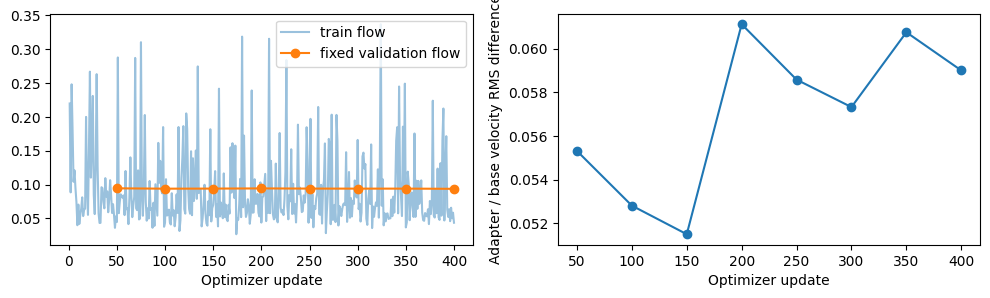

Best flow pointer: {
  "checkpoint": "/content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400",
  "validation_flow": 0.09368839662056416
}


In [5]:
import matplotlib.pyplot as plt
log=[json.loads(line) for line in (RUN/'training_log_v3.jsonl').read_text().splitlines() if line.strip()]
log=sorted({r['step']:r for r in log}.values(),key=lambda r:r['step'])
v=[r for r in log if 'validation' in r]
fig,axes=plt.subplots(1,2,figsize=(12,3))
axes[0].plot([r['step'] for r in log],[r['flow'] for r in log],alpha=.45,label='train flow')
axes[0].plot([r['step'] for r in v],[r['validation']['flow'] for r in v],'o-',label='fixed validation flow')
axes[0].set_xlabel('Optimizer update');axes[0].legend()
axes[1].plot([r['step'] for r in v],[r['validation'].get('adapter_relative_velocity_rms',0) for r in v],'o-')
axes[1].set_xlabel('Optimizer update');axes[1].set_ylabel('Adapter / base velocity RMS difference')
plt.show()
print('Best flow pointer:',(RUN/'best.json').read_text() if (RUN/'best.json').exists() else 'No flow improvement over baseline')

## 9. Lock checkpoint 600 and inspect fixed validation generation
CFG=1 is the default, matching the more promising 17-frame demonstrations. Two fixed seeds are used for each of the four validation prompts. Preserve failures. Checkpoint is pinned to step 600; later changes to `latest.json` cannot alter this evaluation. All these outputs have 81 frames.

This cell defines the preview helper used later. On a resumed notebook you can rerun it, or run its definitions and leave the final preview loop commented if outputs already exist.

In [6]:
from IPython.display import display, Video, Markdown

TARGET_STEP = 400
FINAL_CHECKPOINT = str(
    RUN / 'checkpoints' / f'step_{TARGET_STEP:06d}'
)

metadata_path = Path(FINAL_CHECKPOINT) / 'metadata.json'
assert metadata_path.exists(), f'Train to step {TARGET_STEP} first.'

locked = json.loads(metadata_path.read_text())
assert locked['step'] == TARGET_STEP
assert locked['config']['frames'] == 81

rows = [
    json.loads(line)
    for line in (RUN / 'prepared/index.jsonl').read_text().splitlines()
    if line.strip()
]

val_rows = [r for r in rows if r['split'] == 'val']
byid = {r['id']: r for r in rows}


def preview(clip_id, seeds=(2026, 2027), tag=None):
    if tag is None:
        tag = f'validation_{TARGET_STEP}_cfg1'

    out = RUN / tag

    for seed in seeds:
        run(
            'wan_reverse.sample',
            '--mode', 'student',
            '--checkpoint', FINAL_CHECKPOINT,
            '--id', clip_id,
            '--seed', seed,
            '--out-dir', out
        )

        marker = json.loads(
            (out / 'last_sample.json').read_text()
        )['metadata']

        run('wan_reverse.decode', '--sample', marker)

        print(
            clip_id,
            'seed', seed,
            'Original input:', byid[clip_id]['prompt']
        )
        display(Video(str(Path(marker).with_suffix('.mp4')), embed=True))


for row in val_rows:
    preview(row['id'])

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id fall_08_s00 --seed 2026 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1591.77it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:16<00:00,  8.26s/it]

100%|██████████| 50/50 [03:33<00:00,  4.27s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/fall_08_s00_student_seed2026_e24d67379f.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/fall_08_s

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id fall_08_s00 --seed 2027 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 2061.08it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:18<00:00,  9.29s/it]

100%|██████████| 50/50 [03:33<00:00,  4.27s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/fall_08_s00_student_seed2027_23c427fe5e.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/fall_08_s

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id pour_08_s00 --seed 2026 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 846.91it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:11<00:00,  5.54s/it]

100%|██████████| 50/50 [03:33<00:00,  4.27s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/pour_08_s00_student_seed2026_a7c311dcfa.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/pour_08_s0

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id pour_08_s00 --seed 2027 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1930.19it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:15<00:00,  7.92s/it]

100%|██████████| 50/50 [03:33<00:00,  4.27s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/pour_08_s00_student_seed2027_5514c8a71d.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/pour_08_s

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id ink_08_s00 --seed 2026 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1499.84it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:11<00:00,  5.82s/it]

100%|██████████| 50/50 [03:32<00:00,  4.26s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/ink_08_s00_student_seed2026_35d235f801.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/ink_08_s00_

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id ink_08_s00 --seed 2027 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1698.10it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:16<00:00,  8.32s/it]

100%|██████████| 50/50 [03:33<00:00,  4.28s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/ink_08_s00_student_seed2027_28089c06dc.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/ink_08_s00_

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id inflate_08_s00 --seed 2026 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1382.66it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:11<00:00,  5.54s/it]

100%|██████████| 50/50 [03:32<00:00,  4.25s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/inflate_08_s00_student_seed2026_e8317c445d.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/inf

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --id inflate_08_s00 --seed 2027 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1953.11it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:16<00:00,  8.18s/it]

100%|██████████| 50/50 [03:33<00:00,  4.28s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/inflate_08_s00_student_seed2027_8193b207a4.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --sample /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/validation_400_cfg1/inf

## 10. Final test comparisons and automatic metrics
This generates four fixed test prompts at seed 2026 for the unadapted model and trained student, plus their stored reversed teacher reference. Both networks receive the SAME ORIGINAL prompt. Student output is never frame-reversed. The teacher reference uses all 81 source frames in reverse order at the same spatial/playback format.

The test contexts were viewed in earlier experiments; report that history. Do not select seeds/checkpoints after viewing these results. The fixed validation demo may be highlighted separately as a selected example.

In [7]:
run('wan_refine.probe','--split','test','--checkpoint',FINAL_CHECKPOINT)
run('wan_refine.probe','--split','test','--unadapted')
run('wan_reverse.eval_generate','--split','test','--seed',2026,'--checkpoint',FINAL_CHECKPOINT)
run('wan_reverse.evaluate','--split','test')
EVAL=RUN/'evaluation/test'
print((EVAL/'metrics_summary.json').read_text())
comparisons=[json.loads(line) for line in (EVAL/'comparison_manifest.jsonl').read_text().splitlines() if line.strip()]
for item in comparisons:
    print(item['id'],'Original input:',item['prompt'])
    for mode in ('teacher_reversed_reference','unadapted','student'):
        print(mode,item[mode]);display(Video(item[mode],embed=True))
print('Rate these 12 videos in:',EVAL/'human_review.csv')

Running: /content/wan_reverse_work/env/bin/python -u -m wan_refine.probe --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --split test --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400
Local tensors ready: prepared 40

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1527.98it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:12<00:00,  6.09s/it]
{
  "order_active": 0.65625,
  "motion": 0.16864231502404436,
  "reverse_x0_mse": 0.022394536012143362,
  "order_gap": 0.7475446099415421,
  "adapter_relative_velocity_rms": 0.049323007464408875,
  "order": 0.0,
  "forward_x0_mse": 0.15058708790456876,
  "flow": 0.0782450798433274,
  "reverse_endpoint_closer_fraction": 1.0,
  "order_active_draws": 21,
  "draws": 32,
  "split": "test",
  "mode": "student",
  "checkpoint": "/content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400",
  "note": "Endpoint-order preferenc

unadapted /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/fall_09_s00/unadapted/fall_09_s00_unadapted_seed2026_497fec90af.mp4


student /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/fall_09_s00/student/fall_09_s00_student_seed2026_814b5c40e1.mp4


pour_09_s00 Original input: A realistic close side-view video of pale lemonade pouring from a clear ribbed glass jug into a transparent straight-sided glass, on a green countertop, with soft neutral lighting. The fixed camera includes the complete source container, its spout or mouth, the full receiving glass, and the narrow space between them. The receiving glass stands upright and begins almost empty. There are no other vessels in the scene. The source is tilted above the receiving glass. A continuous visible stream of pale lemonade flows downward from the source mouth into the glass. The liquid level in the receiving glass visibly rises during the shot, leaving a clear difference between the beginning and end. The stream remains inside the rim. Use one continuous shot without a cut, zoom, or camera motion.
teacher_reversed_reference /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/pour_09_s00/teacher_reversed_reference.mp4


unadapted /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/pour_09_s00/unadapted/pour_09_s00_unadapted_seed2026_cc77ba5de5.mp4


...

student /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/ink_09_s00/student/ink_09_s00_student_seed2026_4ab3eb921a.mp4


inflate_09_s00 Original input: A realistic close side-view video of one black latex balloon being inflated above a pale birch tabletop, with a light yellow background and even soft illumination. The balloon neck is attached to a short stationary air nozzle near the center of the tabletop. A small wrinkled balloon is visible at the beginning. The fixed wide framing leaves ample empty space around the balloon for its final expanded shape, with the entire balloon and nozzle always in view. Air enters through the nozzle and the single black balloon visibly expands during the shot. Its body grows from small and wrinkled into a much larger smooth rounded balloon, while its neck stays anchored at the same place. The increase in size happens continuously within this one shot. Preserve the same balloon color and identity. No camera movement, zoom, jump cuts, bursting, extra balloons or hands covering the balloon.
teacher_reversed_reference /content/drive/MyDrive/reverse_video_project/runs/wan_v

unadapted /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/inflate_09_s00/unadapted/inflate_09_s00_unadapted_seed2026_52cf5f8243.mp4


student /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/inflate_09_s00/student/inflate_09_s00_student_seed2026_c74c742831.mp4


Rate these 12 videos in: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/evaluation/test/human_review.csv


## 11. Complete human ratings, summarize, report and export
Edit `runs/wan_v3_81f_600/evaluation/test/human_review.csv` after watching the 12 TEST videos displayed above. For every row, enter inverse-action success 0/1, visual quality 1–5, temporal quality 1–5 and notes. A ball briefly rising or water level changing is insufficient unless the intended inverse action clearly completes. Do not use validation ratings as final test scores.

Run the cell after saving the ratings. Missing fields remain missing. The report records actual artifacts and requires your experimental discussion. Export includes the adapter, pinned base identity, config, logs, diagnostics and available evaluation tables. It does not bundle the pretrained 1.3B base model or raw videos.

In [8]:
run('wan_reverse.human_summary','--split','test')
run('wan_refine.report')
run('wan_reverse.export','--checkpoint',FINAL_CHECKPOINT)
print('Model export:',RUN/'export/wan_reverse_trained_adapter.zip')
print('Stage report:',RUN/'REPORT_V3.md')
display(Markdown((RUN/'REPORT_V3.md').read_text()))

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.human_summary --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json --split test
{
  "teacher_reversed_reference": {
    "rated_action_clips": 0,
    "expected_clips": 4,
    "reverse_action_success_rate": null,
    "visual_quality_mean": null,
    "temporal_quality_mean": null,
    "review_complete": false
  },
  "unadapted": {
    "rated_action_clips": 0,
    "expected_clips": 4,
    "reverse_action_success_rate": null,
    "visual_quality_mean": null,
    "temporal_quality_mean": null,
    "review_complete": false
  },
  "student": {
    "rated_action_clips": 0,
    "expected_clips": 4,
    "reverse_action_success_rate": null,
    "visual_quality_mean": null,
    "temporal_quality_mean": null,
    "review_complete": false
  }
}
Running: /content/wan_reverse_work/env/bin/python -u -m wan_refine.report --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/config.json

# Same-prompt reverse-video refinement: V3 report

Both teacher and student receive the original forward-action prompt. The target is the separately VAE-encoded pixel reversal of the frozen teacher sample. Student sampling and decoding preserve generated frame order.

## Motivation and method

The preceding V2 run produced forward-action outputs in the reviewed tests. V3 uses fresh-noise conditional flow matching, normalized latent-motion reconstruction, and a proposed reverse-versus-forward endpoint hinge. It tests one training clip before a full run. No reverse-caption rewrite is used. See docs/REFINEMENT_MATH_V3.md for equations, assumptions and limitations.

Default kd_weight=0 is teacher-sample distillation. The optional separate transported-velocity-KD ablation must be reported separately. Changes in learning rate, rank, noise sampling and loss mean that this experiment alone does not isolate the cause of the earlier failure.

## Exact configuration

```json
{
  "model_id": "Wan-AI/Wan2.1-T2V-1.3B-Diffusers",
  "revision": "0fad780a534b6463e45facd96134c9f345acfa5b",
  "dataset_dir": "/content/drive/MyDrive/reverse_video_project/data/wan_pilot_v1",
  "work_dir": "/content/wan_reverse_work",
  "run_dir": "/content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600",
  "accept_all_user_declared": true,
  "expected_candidates": 40,
  "height": 256,
  "width": 448,
  "frames": 81,
  "fps": 16,
  "precision": "fp16",
  "rank": 16,
  "lora_alpha": 16,
  "learning_rate": 0.0002,
  "weight_decay": 0.01,
  "max_steps": 600,
  "accumulate": 2,
  "gradient_clip": 1.0,
  "cache_draws_train": 8,
  "cache_draws_eval": 4,
  "conditioning_dropout": 0.1,
  "sigma_min": 0.02,
  "sigma_max": 0.98,
  "flow_weight": 1.0,
  "kd_weight": 0.0,
  "temporal_weight": 0.05,
  "checkpoint_every": 25,
  "validate_every": 50,
  "seed": 20261023,
  "inference_steps": 50,
  "guidance": 1.0,
  "flow_shift": 8.0,
  "conditioning": "original_prompt_reverse_video_v2",
  "method": "fresh-flow-endpoint-order-v3",
  "phase": "full",
  "require_all_81_frames": true,
  "validation_draws": 8,
  "validation_seed": 20261024,
  "train_ids": [
    "fall_00_s00",
    "fall_01_s00",
    "fall_02_s00",
    "fall_03_s00",
    "fall_04_s00",
    "fall_05_s00",
    "fall_06_s00",
    "fall_07_s00",
    "pour_00_s00",
    "pour_01_s00",
    "pour_02_s00",
    "pour_03_s00",
    "pour_04_s00",
    "pour_05_s00",
    "pour_06_s00",
    "pour_07_s00",
    "ink_00_s00",
    "ink_01_s00",
    "ink_02_s00",
    "ink_03_s00",
    "ink_04_s00",
    "ink_05_s00",
    "ink_06_s00",
    "ink_07_s00",
    "inflate_00_s00",
    "inflate_01_s00",
    "inflate_02_s00",
    "inflate_03_s00",
    "inflate_04_s00",
    "inflate_05_s00",
    "inflate_06_s00",
    "inflate_07_s00"
  ],
  "motion_weight": 0.1,
  "motion_floor": 0.05,
  "order_weight": 0.1,
  "order_margin": 0.2,
  "order_floor": 0.01,
  "min_pair_separation": 0.0001,
  "order_sigma_min": 0.2,
  "order_sigma_max": 0.85,
  "kd_every": 4
}
```

## gpu_smoke_v3.json

```json
{
  "signature": "033209a123ae1e58e166f52b69e6b6f3d4240f2f3bff6595008125f2efeccf19",
  "gpu": "Tesla T4",
  "loss": 0.051459901034832,
  "gradient_norm": 0.013829592615365982,
  "adapter_max_change": 0.00019999837968498468,
  "reload_max_abs_error": 0.0,
  "peak_gpu_gib": 4.954029083251953,
  "microbatch_update_seconds": 16.247290827999905,
  "frames": 81,
  "height": 256,
  "width": 448,
  "latent_shape": [
    1,
    16,
    21,
    32,
    56
  ],
  "rough_train_compute_hours_excluding_validation": 5.415763609333301,
  "trainable_parameters": 11796480,
  "adapted_modules": 240,
  "note": "Execution check, not reverse-motion learning evidence."
}
```

## baseline_validation.json

```json
{
  "motion": 0.23323792353039607,
  "reverse_x0_mse": 0.02965372171092895,
  "order": 0.0,
  "forward_x0_mse": 0.36092871538130566,
  "adapter_relative_velocity_rms": 0.0,
  "order_gap": 0.7933205246226862,
  "flow": 0.10219047626014799,
  "order_active": 0.6875,
  "reverse_endpoint_closer_fraction": 1.0,
  "order_active_draws": 22,
  "draws": 32
}
```

## training_complete.json

NOT RUN / NOT AVAILABLE

## best.json

```json
{
  "checkpoint": "/content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400",
  "validation_flow": 0.09368839662056416
}
```

## latest.json

```json
{
  "checkpoint": "/content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400"
}
```

## diagnostics/train_student.json

NOT RUN / NOT AVAILABLE

## diagnostics/val_student.json

NOT RUN / NOT AVAILABLE

## diagnostics/test_student.json

```json
{
  "order_active": 0.65625,
  "motion": 0.16864231502404436,
  "reverse_x0_mse": 0.022394536012143362,
  "order_gap": 0.7475446099415421,
  "adapter_relative_velocity_rms": 0.049323007464408875,
  "order": 0.0,
  "forward_x0_mse": 0.15058708790456876,
  "flow": 0.0782450798433274,
  "reverse_endpoint_closer_fraction": 1.0,
  "order_active_draws": 21,
  "draws": 32,
  "split": "test",
  "mode": "student",
  "checkpoint": "/content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400",
  "note": "Endpoint-order preference on noised real targets; not free-generation reverse-action success."
}
```

## diagnostics/test_unadapted.json

```json
{
  "reverse_x0_mse": 0.025100022638071096,
  "order_active": 0.65625,
  "flow": 0.08514227683190256,
  "order_gap": 0.7541420171037316,
  "motion": 0.1981980872224085,
  "order": 0.0,
  "forward_x0_mse": 0.15356528194388375,
  "reverse_endpoint_closer_fraction": 1.0,
  "order_active_draws": 21,
  "draws": 32,
  "split": "test",
  "mode": "unadapted",
  "checkpoint": "latest",
  "note": "Endpoint-order preference on noised real targets; not free-generation reverse-action success."
}
```

## evaluation/test/metrics_summary.json

```json
{
  "metrics": {
    "teacher_reversed_reference": {
      "n": 4,
      "warp_l1": 0.002618464566949828,
      "flow_magnitude_pixels": 0.16290287977608386,
      "clip_text_cosine": 0.30083996802568436
    },
    "unadapted": {
      "n": 4,
      "warp_l1": 0.024343810885706366,
      "flow_magnitude_pixels": 1.3458848010166546,
      "clip_text_cosine": 0.26811354979872704
    },
    "student": {
      "n": 4,
      "warp_l1": 0.005118989084719443,
      "flow_magnitude_pixels": 0.3160800283192657,
      "clip_text_cosine": 0.2938978672027588
    }
  },
  "limitations": [
    "CLIP averaged over frames is not a temporal direction test.",
    "Low warp error can reward a static video; inspect flow magnitude and action success together.",
    "Optical flow includes camera motion, occlusions and lighting changes.",
    "Only four test contexts: do not treat the averages as robust population estimates.",
    "Teacher reference is a resized, temporally subsampled stored video; it is not a new matched-noise generation."
  ]
}
```

## evaluation/test/human_summary.json

```json
{
  "teacher_reversed_reference": {
    "rated_action_clips": 0,
    "expected_clips": 4,
    "reverse_action_success_rate": null,
    "visual_quality_mean": null,
    "temporal_quality_mean": null,
    "review_complete": false
  },
  "unadapted": {
    "rated_action_clips": 0,
    "expected_clips": 4,
    "reverse_action_success_rate": null,
    "visual_quality_mean": null,
    "temporal_quality_mean": null,
    "review_complete": false
  },
  "student": {
    "rated_action_clips": 0,
    "expected_clips": 4,
    "reverse_action_success_rate": null,
    "visual_quality_mean": null,
    "temporal_quality_mean": null,
    "review_complete": false
  }
}
```

## Training log

400 distinct logged updates; highest logged step 400. Logs may include repeated uncommitted steps after a disconnect. Latest committed checkpoint is identified above.

## Qualitative assessment and discussion — COMPLETE FROM OBSERVATIONS

Record whether forward/reverse VAE reconstructions retain the intended action. Show both fixed diagnostic seeds, validation comparisons and every final test clip, including failures. Record visible inverse-action completion rather than relying on reconstruction proxies. Explain checkpoint selection using validation, settings/compute, experiments, and failure cases.

## Interface and submission

notebooks/Wan_Reverse_Refine_V3_Colab.ipynb section 15 takes an original prompt and seed, uses saved original embeddings or a frozen text encoder, runs the trained LoRA transformer and decodes frames without reversing them. It displays video and saved human metrics if available. Submit source, dependency pins, adapter/base revision, exact configuration, training log, diagnostics, videos, completed ratings and this completed report.

## Limits

Only 32 training clips and four test contexts; test clips were already inspected in V2. The endpoint hinge can exploit non-motion appearance or causal-boundary differences. One-clip success can be memorization. LoRA keeps the full base architecture and does not imply inference acceleration. Full-model GPU execution and reverse-motion quality must be established by the saved experiment, not by the CPU component tests.


## 12. Interactive demo: original action prompt → direct student video
The demo is pinned to the new 81-frame checkpoint 600 and CFG=1. It does not secretly use a successful 17-frame clip. The default ink validation prompt is an example; its 81-frame quality must be inspected before calling it a best result. You can select any saved original prompt, edit it or enter a new prompt, and choose a seed.

New text is encoded unchanged by the frozen text encoder in a separate process. First use may need large model downloads. Choosing a cached prompt avoids that load. A requested side-by-side unadapted comparison uses the same input, seed and sampling settings. The interface shows measured compute time and saved test metrics when available. These are experiment summaries, not correctness scores for the newly generated video.

In [10]:
import json
import hashlib
from pathlib import Path

import ipywidgets as widgets
from IPython.display import display, Video
from google.colab import output as colab_output

colab_output.enable_custom_widget_manager()

TARGET_STEP = 400
FINAL_CHECKPOINT = str(
    RUN / "checkpoints" / f"step_{TARGET_STEP:06d}"
)

metadata_path = Path(FINAL_CHECKPOINT) / "metadata.json"
assert metadata_path.exists(), f"Finish {TARGET_STEP} updates first."

locked = json.loads(metadata_path.read_text())
assert locked["step"] == TARGET_STEP
assert locked["config"]["frames"] == 81

# Sampling configuration only; training config remains unchanged.
demo_settings = json.loads(Path(CFG).read_text())
demo_settings["guidance"] = 1.0

DEMO_CFG = RUN / "demo_cfg1.json"
DEMO_CFG.write_text(json.dumps(demo_settings, indent=2))

rows = [
    json.loads(line)
    for line in (RUN / "prepared/index.jsonl").read_text().splitlines()
    if line.strip()
]
byid = {r["id"]: r for r in rows}

dataset_dir = Path(demo_settings["dataset_dir"])
records = [
    json.loads(line)
    for line in (dataset_dir / "manifest_wan.jsonl").read_text().splitlines()
    if line.strip()
]
teacher_records = {r["id"]: r for r in records}

default = "ink_08_s00" if "ink_08_s00" in byid else rows[0]["id"]

selector = widgets.Dropdown(
    options=[
        (f"{r['event']} | {r['id']} | {r['split']}", r["id"])
        for r in rows
    ],
    value=default,
    description="Example:"
)

prompt_box = widgets.Textarea(
    value=byid[default]["prompt"],
    description="Prompt:",
    layout=widgets.Layout(width="95%", height="140px")
)

seed_box = widgets.IntText(value=2026, description="Seed:")

fresh_teacher_box = widgets.Checkbox(
    value=False,
    description="Generate fresh teacher video with the selected seed",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="95%")
)

button = widgets.Button(
    description="Show teacher and student",
    button_style="primary",
    layout=widgets.Layout(width="250px")
)

result = widgets.Output()


def select_prompt(change):
    prompt_box.value = byid[change["new"]]["prompt"]


selector.observe(select_prompt, names="value")


def generate_video(mode, args, seed):
    folder = "teacher_forward" if mode == "unadapted" else "student"
    out = RUN / "demo" / folder
    out.mkdir(parents=True, exist_ok=True)

    run(
        "wan_reverse.sample",
        "--mode", mode,
        "--checkpoint", FINAL_CHECKPOINT,
        *args,
        "--seed", seed,
        "--out-dir", out,
        config_path=DEMO_CFG
    )

    marker = json.loads(
        (out / "last_sample.json").read_text()
    )["metadata"]

    run(
        "wan_reverse.decode",
        "--sample", marker,
        config_path=DEMO_CFG
    )

    video = Path(marker).with_suffix(".mp4")
    timing = json.loads(
        video.with_suffix(".decoded.json").read_text()
    )
    return video, timing


def generate_clicked(_):
    button.disabled = True

    with result:
        result.clear_output(wait=True)

        try:
            text = prompt_box.value.strip()
            if not text:
                raise ValueError("Enter the original forward-action prompt.")

            seed = int(seed_box.value)
            selected = byid[selector.value]

            cached_id = (
                selected["id"]
                if text == selected["prompt"]
                else next(
                    (r["id"] for r in rows if r["prompt"] == text),
                    None
                )
            )

            demo = RUN / "demo"
            demo.mkdir(parents=True, exist_ok=True)

            if cached_id is not None:
                args = ["--id", cached_id]
            else:
                embedding = demo / (
                    "prompt_"
                    + hashlib.sha256(text.encode()).hexdigest()[:16]
                    + ".safetensors"
                )

                run(
                    "wan_reverse.encode_text",
                    "--prompt", text,
                    "--out", embedding,
                    config_path=DEMO_CFG
                )
                args = ["--embedding", embedding, "--prompt", text]

            print("Original prompt:", text)

            # Teacher forward video.
            display(widgets.HTML("<h3>Teacher — forward video</h3>"))

            if cached_id is not None and not fresh_teacher_box.value:
                record = teacher_records[cached_id]
                teacher_video = (
                    dataset_dir / record["assets"]["forward"]["path"]
                )

                if not teacher_video.exists():
                    raise FileNotFoundError(str(teacher_video))

                display(Video(str(teacher_video), embed=True, width=560))
                print("Saved teacher video | Original seed:", record.get("seed"))
                print(
                    "Uses the original teacher generation settings. "
                    "Select the checkbox for a fresh matched-settings comparison."
                )
            else:
                video, timing = generate_video("unadapted", args, seed)
                display(Video(str(video), embed=True, width=560))
                print("Fresh frozen teacher | Seed:", seed, "| CFG: 1")
                print(
                    "Generation + decoding:",
                    round(timing["total_compute_seconds"], 1),
                    "seconds"
                )

            # Student direct output, without frame reversal.
            display(widgets.HTML(
                "<h3>Student — direct reverse-time output</h3>"
            ))

            video, timing = generate_video("student", args, seed)
            display(Video(str(video), embed=True, width=560))

            print(
                f"Checkpoint: {TARGET_STEP} | Seed: {seed} | CFG: 1"
            )
            print(
                "Generation + decoding:",
                round(timing["total_compute_seconds"], 1),
                "seconds"
            )
            print(
                "Frames:", timing["frame_count"],
                "| Playback fps:", timing["fps"]
            )
            print("Saved:", video)

            # Saved test metrics, if available.
            human = RUN / "evaluation/test/human_summary.json"
            if human.exists():
                values = json.loads(human.read_text()).get("student", {})
                rate = values.get("reverse_action_success_rate")

                if rate is not None:
                    print(
                        "Test inverse-action success:",
                        f"{rate:.0%}",
                        "| Rated clips:", values.get("rated_action_clips")
                    )

            automatic = RUN / "evaluation/test/metrics_summary.json"
            if automatic.exists():
                values = json.loads(
                    automatic.read_text()
                )["metrics"]["student"]

                cosine = values.get("clip_text_cosine")
                if cosine is not None:
                    print(
                        "Test inverse-event CLIP cosine (proxy):",
                        round(cosine, 3)
                    )

            print(
                "Test metrics describe the evaluated set, "
                "not this individual video's correctness."
            )

        except Exception as error:
            print(type(error).__name__ + ":", error)

        finally:
            button.disabled = False


button.on_click(generate_clicked)

display(
    widgets.HTML(
        f"<h3>Teacher forward vs student reverse-time — "
        f"checkpoint {TARGET_STEP}</h3>"
        "<p>Both use the original forward-action prompt. "
        "Student frames are displayed without reversal. "
        "Successful inverse motion is not guaranteed.</p>"
    ),
    selector,
    prompt_box,
    seed_box,
    fresh_teacher_box,
    button,
    result
)

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.encode_text --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo_cfg1.json --prompt glass vessel breaking into pieces --out /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/prompt_71055ec96513f675.safetensors


Loading checkpoint shards: 100%|██████████| 5/5 [01:31<00:00, 18.23s/it]
Prompt encoded. Model released when this process exits.
Original prompt: glass vessel breaking into pieces


HTML(value='<h3>Teacher — forward video</h3>')

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo_cfg1.json --mode unadapted --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --embedding /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/prompt_71055ec96513f675.safetensors --prompt glass vessel breaking into pieces --seed 2026 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/teacher_forward

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 1800.90it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:13<00:00,  6.67s/it]

100%|██████████| 50/50 [03:05<00:00,  3.71s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/teacher_forward/custom_ddf78c7b82ce_unadapted_seed2026_3879e5ef10.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDr

Fresh frozen teacher | Seed: 2026 | CFG: 1
Generation + decoding: 230.9 seconds


HTML(value='<h3>Student — direct reverse-time output</h3>')

Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.sample --config /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo_cfg1.json --mode student --checkpoint /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/checkpoints/step_000400 --embedding /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/prompt_71055ec96513f675.safetensors --prompt glass vessel breaking into pieces --seed 2026 --out-dir /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/student

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 2145.42it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:16<00:00,  8.32s/it]

100%|██████████| 50/50 [03:33<00:00,  4.28s/it]
Latent ready: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/student/custom_ddf78c7b82ce_student_seed2026_fd1b73f081.json
Running: /content/wan_reverse_work/env/bin/python -u -m wan_reverse.decode --config /content/drive/MyDrive/reverse_video_pr

Checkpoint: 400 | Seed: 2026 | CFG: 1
Generation + decoding: 260.6 seconds
Frames: 81 | Playback fps: 16
Saved: /content/drive/MyDrive/reverse_video_project/runs/wan_v3_81f_600/demo/student/custom_ddf78c7b82ce_student_seed2026_fd1b73f081.mp4
Test inverse-event CLIP cosine (proxy): 0.294
Test metrics describe the evaluated set, not this individual video's correctness.


## Resume after a disconnected or replaced Colab runtime
Rerun sections **1–3** to mount the correct Drive, restore the isolated environment/config and verify the dataset. Restore these lightweight variables before jumping to generation/demo:
```python
rows=[json.loads(line) for line in (RUN/'prepared/index.jsonl').read_text().splitlines() if line.strip()]
FINAL_CHECKPOINT=str(RUN/'checkpoints/step_000600')
```
Then:
- Interrupted preparation: rerun section 5 (or 4 first if no successful smoke exists).
- Interrupted training: rerun section 7. It resumes the latest committed 81-frame checkpoint, repeating at most the uncommitted interval.
- Completed training: jump to the needed evaluation/export/demo cell. No need to repeat training or teacher video generation.
- Moving this new run to another Drive: copy the entire new run including prepared tensors, configs, pointer JSONs and checkpoints, plus the same dataset/source, retaining the same `MyDrive/reverse_video_project` layout. Wait for syncing before mounting it. This creates independent copies, not automatic synchronization.

The old Drive tree does not need `runs/wan_v3_full` or `runs/wan_v3_overfit` for this experiment. Keep them on the original Drive as the 17-frame baseline. If the full 81-frame smoke does not fit a T4, use a GPU with more memory or explicitly create a new lower-spatial-resolution 81-frame experiment; do not continue using a failed smoke record.